Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.
Classes: 102
229/229 ━━━━━━━━━━━━━━━━━━━━ 3352s 15s/step - accuracy: 0.5817 - loss: 1.9396 - val_accuracy: 0.7183 - val_loss: 1.1236
58/58 ━━━━━━━━━━━━━━━━━━━━ 586s 10s/step - accuracy: 0.7183 - loss: 1.1236
Loss: 1.1235613822937012
Accuracy: 0.7182713150978088


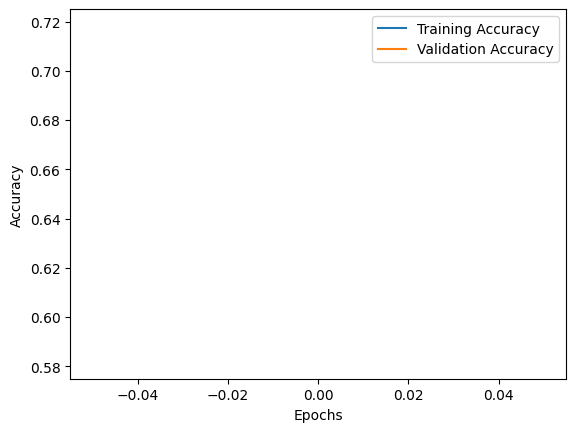

1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step


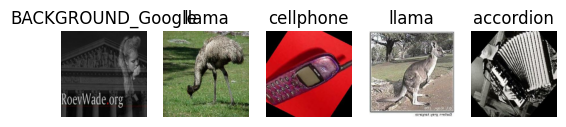

 50/229 ━━━━━━━━━━━━━━━━━━━━ 1:47:49 36s/step - accuracy: 0.8319 - loss: 0.6346

In [ ]:
# 1. Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

# 2. Load dataset (change path for 5A / 5B)
data_dir = r"F:\lp4\LP IV Updated Datasets\Object Detection\caltech-101"
sd

train_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42
)

class_names = train_ds.class_names
print("Classes:", len(class_names))

# 3. Load pretrained VGG16
base_model = keras.applications.VGG16(
    weights=None,
    include_top=False,
    input_shape=(224,224,3)
)

base_model.load_weights(r"F:\lp4\LP IV Updated Datasets\Object Detection\vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")

# 4. Freeze base model and add custom layers
base_model.trainable = False

model = keras.Sequential([
    keras.Input(shape=(224,224,3)),
    layers.Rescaling(1./255),
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

# 5. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1
)

# 7. Evaluate model
loss, accuracy = model.evaluate(val_ds)
print("Loss:", loss)
print("Accuracy:", accuracy)

# 8. Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 9. Visualize predictions
for images, labels in val_ds.take(1):
    predictions = model.predict(images)

    for i in range(5):
        predicted_class = np.argmax(predictions[i])

        plt.subplot(1,5,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[predicted_class])
        plt.xlabel("Actual: " + class_names[int(labels[i])])
        plt.axis('off')

    plt.show()

# 10. Fine-tune model
base_model.trainable = True

for layer in base_model.layers[:-4]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1
)

In [ ]:
plt.plot(history.history['accuracy'], marker='o',label='Training Accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
